In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [2]:
df = pd.read_csv('karnataka_crop_dataset_V2.csv')
print('Dataset Loaded Successfully')

Dataset Loaded Successfully


In [3]:
df

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,blackgram
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,mango
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,horsegram
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,chickpea
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,sapota
...,...,...,...,...,...,...,...,...,...,...,...,...
21955,31.41,40.06,74.51,21.26,58.43,7.21,474.30,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate
21956,37.96,47.12,52.83,29.05,31.77,5.59,416.11,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate
21957,43.33,27.69,47.62,31.40,30.01,7.11,223.77,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate
21958,35.74,31.59,59.39,25.10,41.22,7.43,392.47,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate


In [4]:
df.head() #first 5 row


,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,blackgram
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,mango
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,horsegram
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,chickpea
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,sapota


### Dataset Understanding

In [5]:
df.shape # Check dataset shape (rows, columns)

(21960, 12)

In [6]:
df.info()# check dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21960 entries, 0 to 21959
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            21960 non-null  float64
 1   P            21960 non-null  float64
 2   K            21960 non-null  float64
 3   temperature  21960 non-null  float64
 4   humidity     21960 non-null  float64
 5   ph           21960 non-null  float64
 6   rainfall     21960 non-null  float64
 7   soil_type    21960 non-null  object 
 8   season       21960 non-null  object 
 9   district     21960 non-null  object 
 10  region       21960 non-null  object 
 11  label        21960 non-null  object 
dtypes: float64(7), object(5)
memory usage: 2.0+ MB


### Check Missing Values

In [7]:

df.isnull().sum()


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
soil_type      0
season         0
district       0
region         0
label          0
dtype: int64

## check Duplicate Values

In [8]:
df.duplicated().sum()

np.int64(0)

### EDA

In [9]:
df.describe() # statistical summary

,N,P,K,temperature,humidity,ph,rainfall
count,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000
mean,87.385183,44.173338,81.801056,26.726448,64.884968,6.440398,475.729599
std,51.958329,13.352457,45.960210,3.810617,13.029716,0.505544,629.358431
min,15.000000,20.000000,15.020000,15.010000,30.010000,4.530000,53.740000
25%,53.387500,37.290000,46.280000,24.170000,55.680000,6.110000,156.357500
50%,76.980000,43.000000,68.520000,26.480000,65.020000,6.450000,283.490000
75%,113.212500,50.030000,108.040000,29.212500,75.130000,6.780000,430.142500
max,279.780000,99.950000,199.990000,37.990000,95.000000,8.000000,3678.950000


In [10]:
df.describe(include='object') # Categorical Data Analysis

,soil_type,season,district,region,label
count,21960,21960,21960,21960,21960
unique,6,3,31,4,39
top,Red,Kharif,Bagalkote,North Karnataka,banana
freq,6582,10060,1580,9200,1200


### Data Visualization


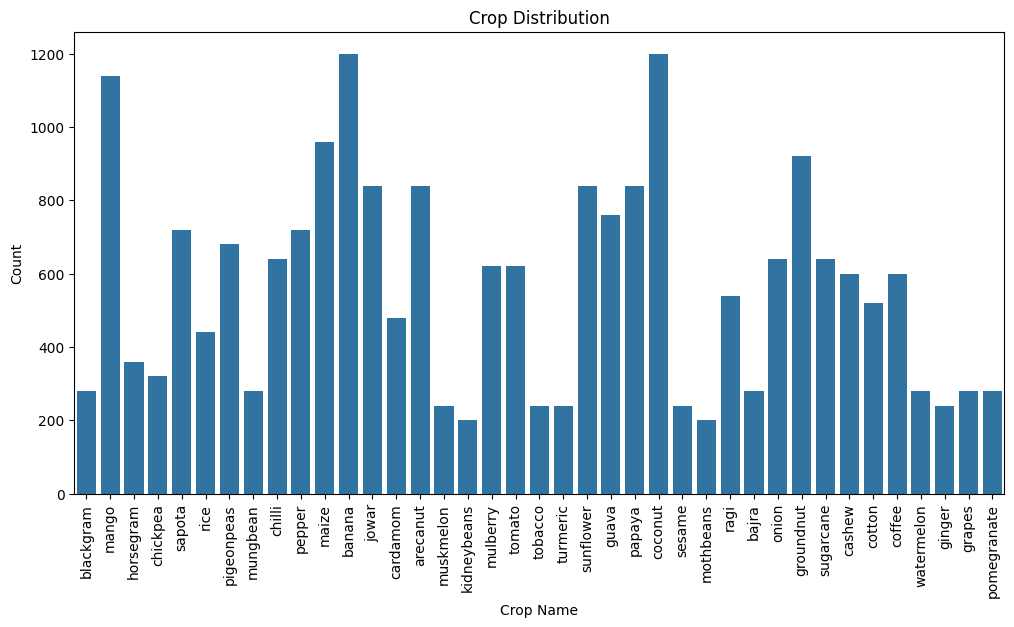

In [11]:
plt.figure(figsize=(12,6)) # graph size
sns.countplot(data=df, x='label')# crop count

plt.title('Crop Distribution') # graph title
plt.xlabel('Crop Name')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

### Numerical features Distribution

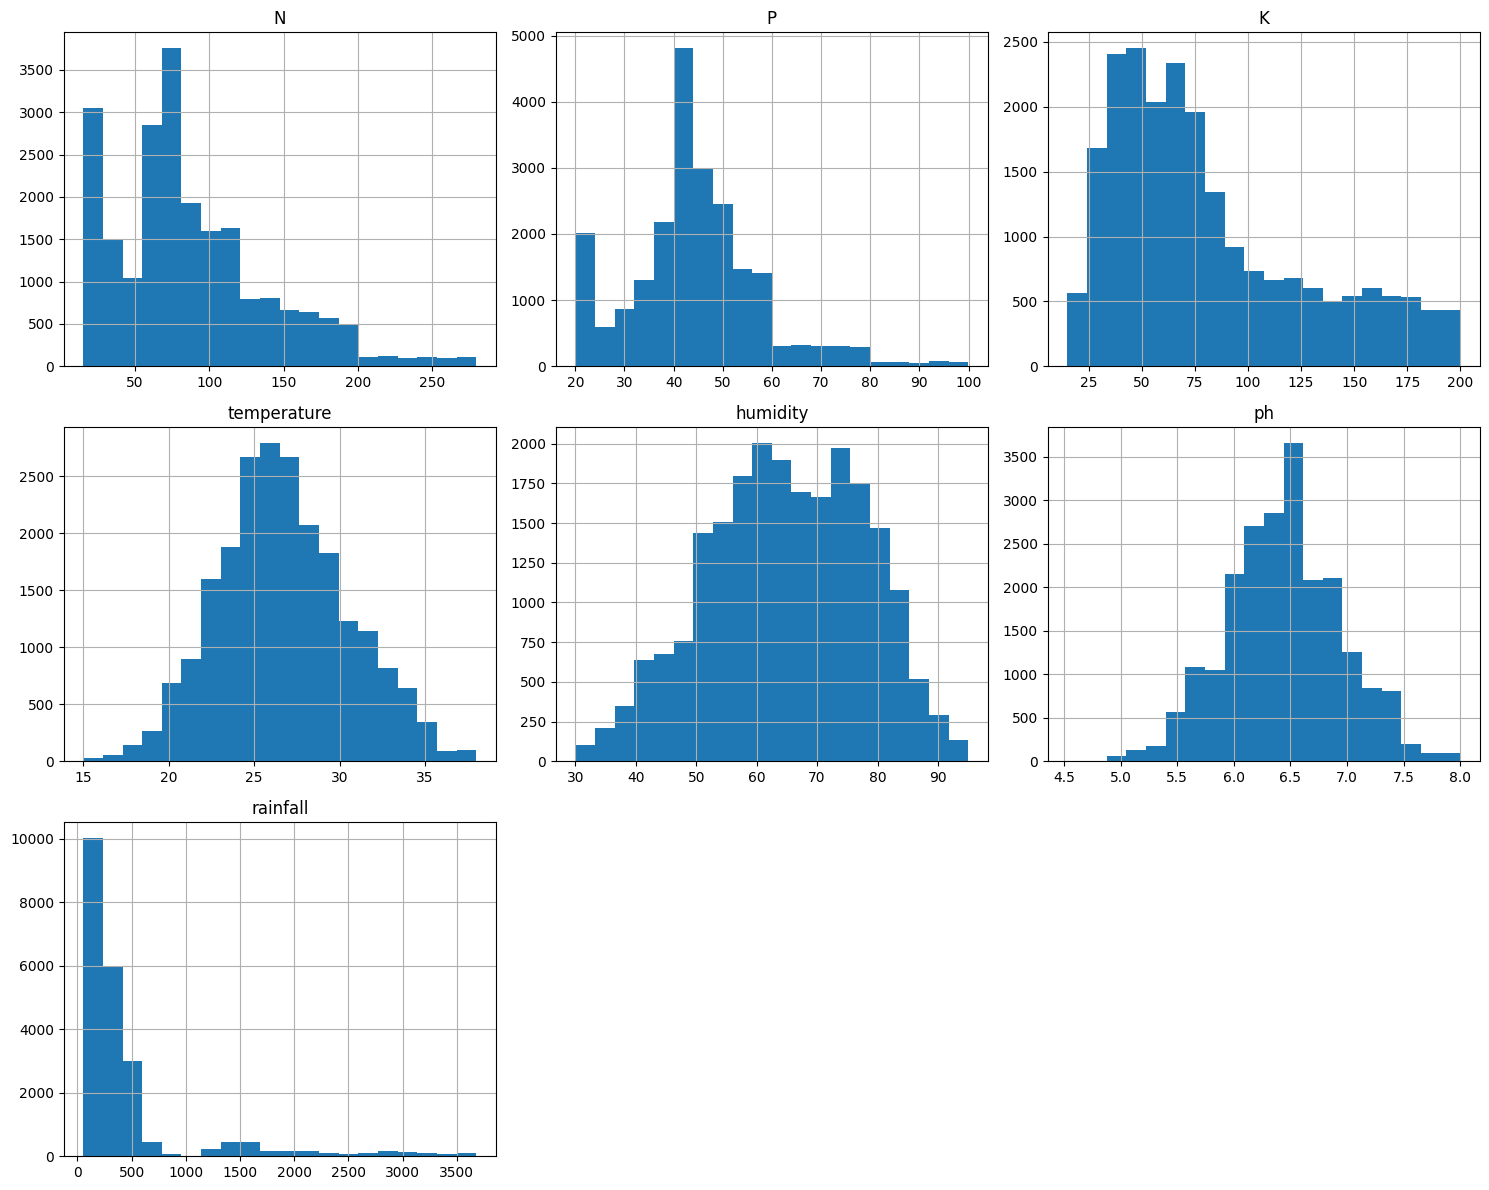

In [12]:
df.hist(figsize=(15,12), bins=20)
plt.tight_layout()
plt.show()

### Outlier Detection(Boxplot)

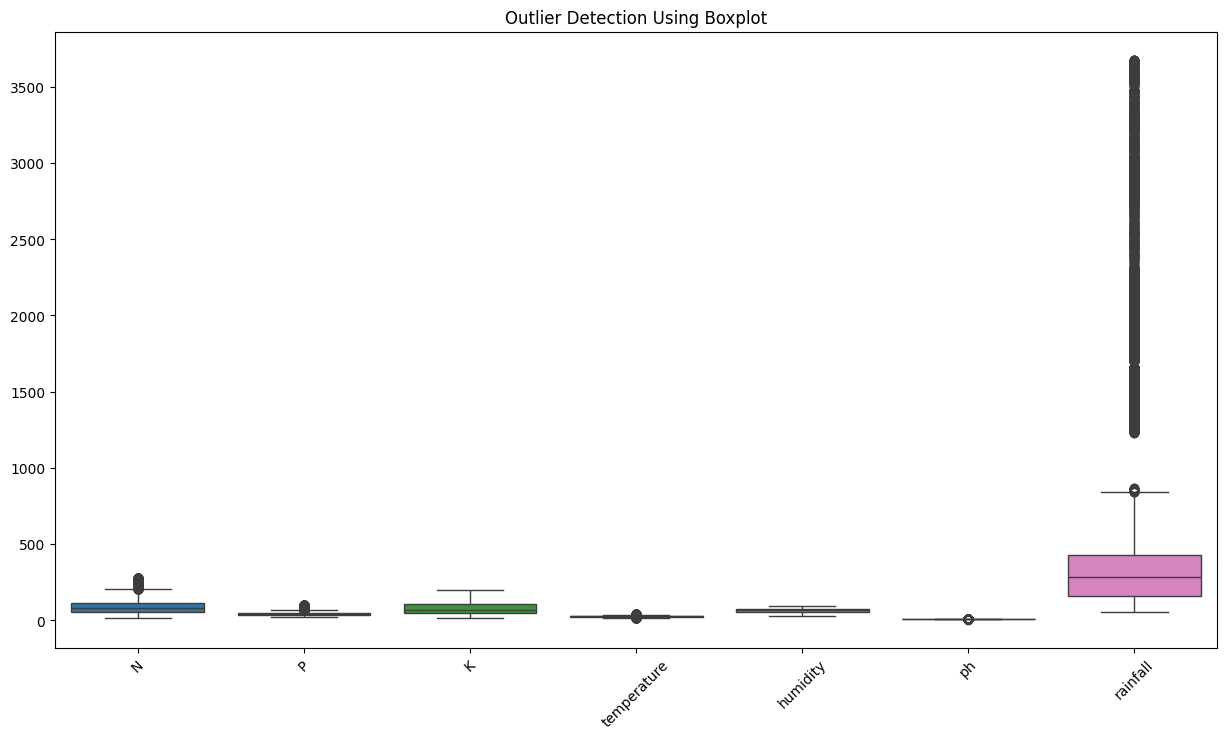

In [13]:
plt.figure(figsize=(15,8))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.title('Outlier Detection Using Boxplot')
plt.xticks(rotation=45)
plt.show()

### Correlation Analysis

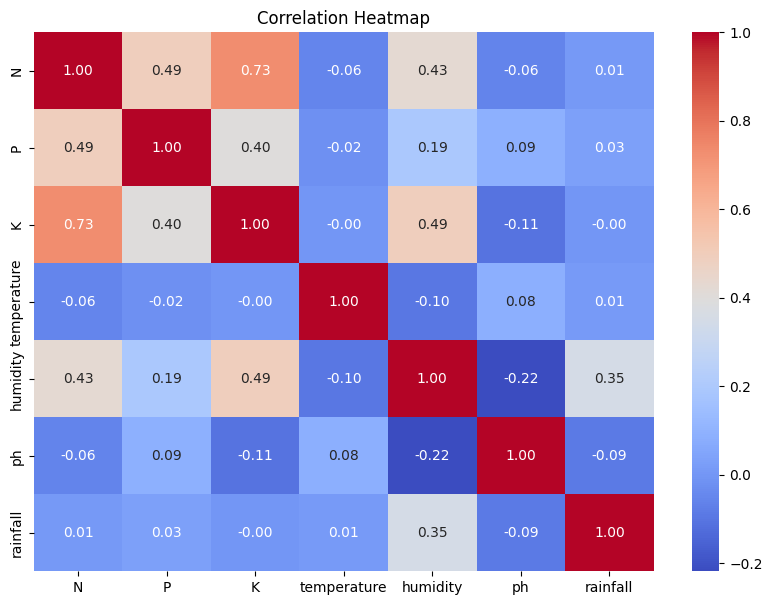

In [14]:
plt.figure(figsize=(10,7))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

### Categorical Data Visualization

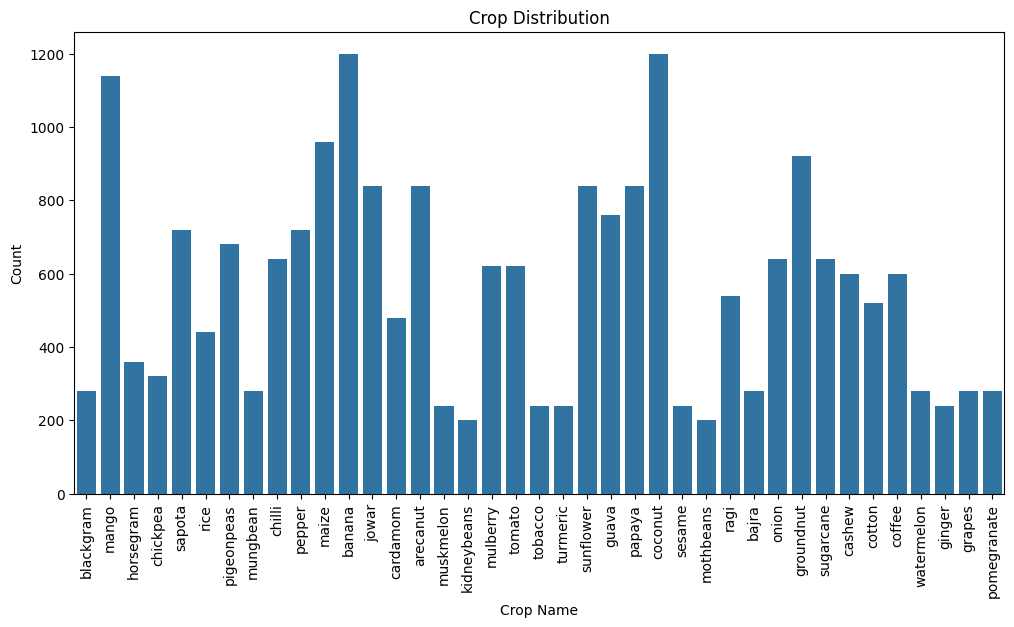

In [15]:
plt.figure(figsize=(12,6))

sns.countplot(data=df, x='label')

plt.title('Crop Distribution')
plt.xlabel('Crop Name')
plt.ylabel('Count')
plt.xticks(rotation=90)

plt.show()

#### Soil type,Season,District,Region Visualization

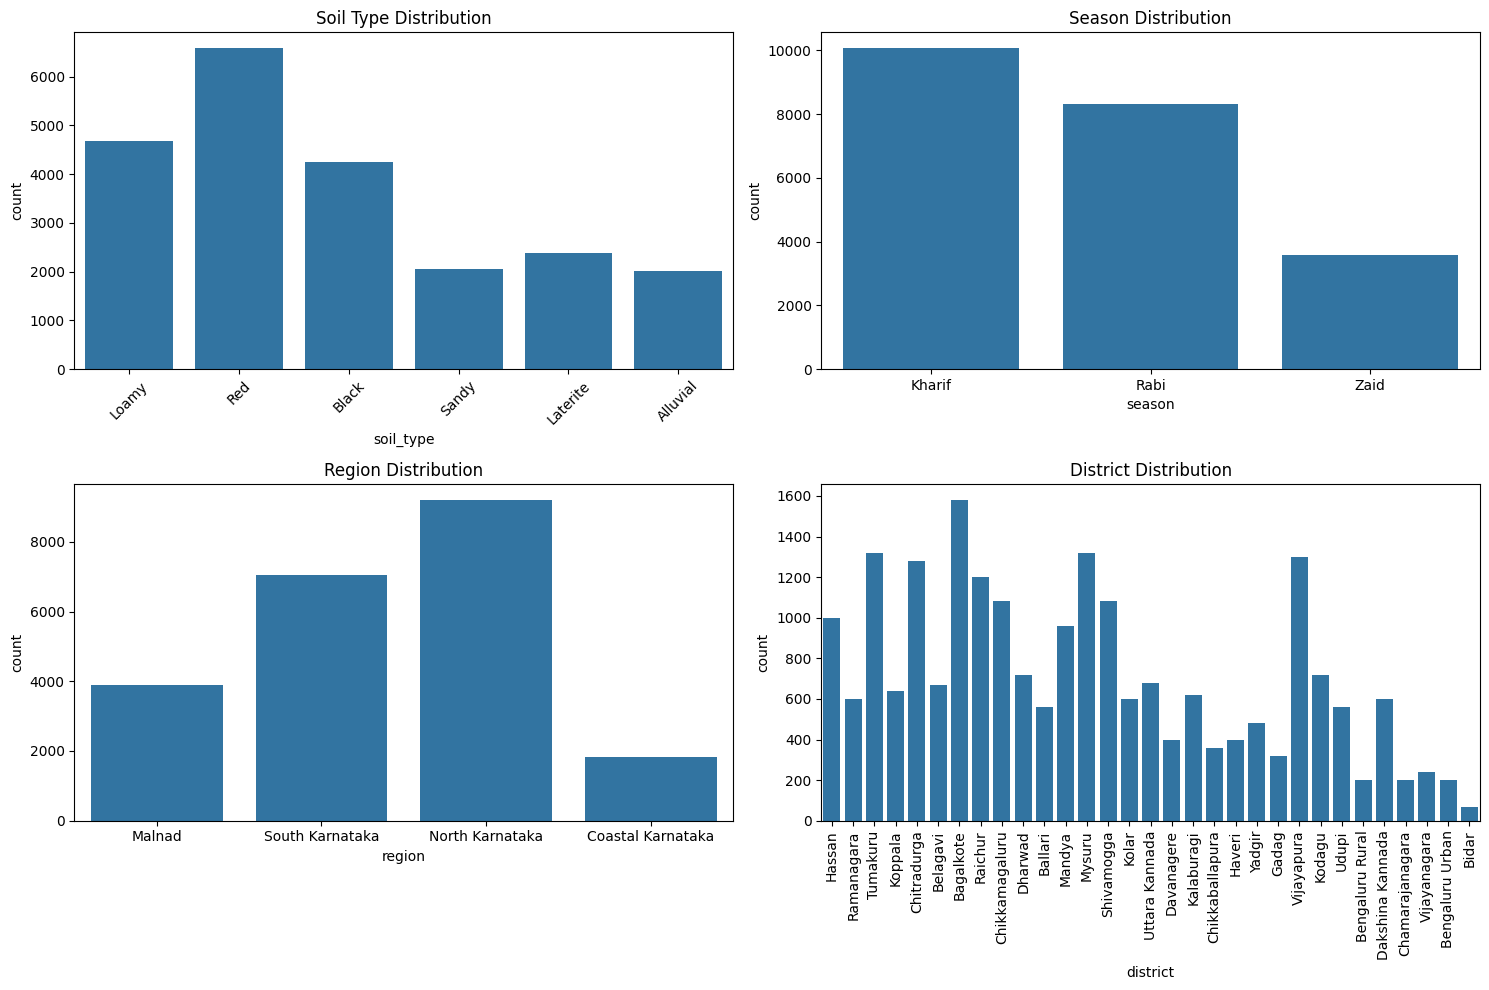

In [16]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
sns.countplot(data=df, x='soil_type')
plt.title('Soil Type Distribution')
plt.xticks(rotation=45)

plt.subplot(2, 2, 2)
sns.countplot(data=df, x='season')
plt.title('Season Distribution')

plt.subplot(2, 2, 3)
sns.countplot(data=df, x='region')
plt.title('Region Distribution')

plt.subplot(2, 2, 4)
sns.countplot(data=df, x='district')
plt.title('District Distribution')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# EDA SUMMARY

1. Dataset contains 21,960 rows and 12 columns.

2. There are 7 numerical columns and 5 categorical columns.

3. No missing values were found.

4. No duplicate records were found.

5. The dataset contains 39 different crop categories.

6. Numerical statistical analysis was performed.

7. Crop distribution was visualized using a count plot.

8. Numerical features were analyzed using histograms.

9. Outliers were detected using boxplots.

10. Correlation analysis was performed using a heatmap.

11. Categorical features were visualized using count plots.

12. Red soil and Kharif season have the highest frequency.

13. North Karnataka has the highest regional frequency.

### DATA PREPROCESSING

In [17]:
# Create a copy of the original dataset

df1 = df.copy()

print("Dataset copied successfully")

print("Original Dataset Shape:", df.shape)

print("New Dataset Shape:", df1.shape)

Dataset copied successfully
Original Dataset Shape: (21960, 12)
New Dataset Shape: (21960, 12)


### Handling Missing Values

In [18]:
# check missing values
df1.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
soil_type      0
season         0
district       0
region         0
label          0
dtype: int64

### Handling Duplicate Values

In [19]:
# check duplicate values
print("Duplicate Rows:",df1.duplicated().sum())

Duplicate Rows: 0


### Handling Outliers

In [20]:
# Detect Outliers using IQR

numerical_cols = df1.select_dtypes(include='number').columns

for col in numerical_cols:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df1[(df1[col] < lower) | (df1[col] > upper)]

    print(col, ":", len(outliers))

N : 617
P : 1132
K : 0
temperature : 155
humidity : 0
ph : 236
rainfall : 2465


In [21]:
# Check Outlier Range

for col in numerical_cols:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df1[(df1[col] < lower) | (df1[col] > upper)]

    if len(outliers) > 0:
        print("\n", col)
        print("Minimum Outlier:", outliers[col].min())
        print("Maximum Outlier:", outliers[col].max())
        #“Outliers were detected using the IQR method. Since these values may represent valid agricultural conditions, they were retained without removal.”


 N
Minimum Outlier: 202.96
Maximum Outlier: 279.78

 P
Minimum Outlier: 69.15
Maximum Outlier: 99.95

 temperature
Minimum Outlier: 15.01
Maximum Outlier: 37.99

 ph
Minimum Outlier: 4.53
Maximum Outlier: 8.0

 rainfall
Minimum Outlier: 840.98
Maximum Outlier: 3678.95


### Encoding Categorical Variables

In [22]:
#Label encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df1['label'] = le.fit_transform(df1['label'])

In [23]:
df1.head()

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,3
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,19
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,15
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,6
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,31


In [24]:
df1.shape

(21960, 12)

### Feature and Target Separation

In [25]:
# Separate input and output variables

X = df1.drop('label', axis=1)
y = df1['label']

print("X Shape:", X.shape)
print("y Shape:", y.shape)


X Shape: (21960, 11)
y Shape: (21960,)


In [26]:
X

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka
...,...,...,...,...,...,...,...,...,...,...,...
21955,31.41,40.06,74.51,21.26,58.43,7.21,474.30,Sandy,Rabi,Kalaburagi,North Karnataka
21956,37.96,47.12,52.83,29.05,31.77,5.59,416.11,Sandy,Rabi,Kalaburagi,North Karnataka
21957,43.33,27.69,47.62,31.40,30.01,7.11,223.77,Sandy,Rabi,Kalaburagi,North Karnataka
21958,35.74,31.59,59.39,25.10,41.22,7.43,392.47,Sandy,Rabi,Kalaburagi,North Karnataka


In [27]:
y

0         3
1        19
2        15
3         6
4        31
         ..
21955    28
21956    28
21957    28
21958    28
21959    28
Name: label, Length: 21960, dtype: int64

In [28]:


# check shape
print("x Shape:", X.shape)
print("y Shape:", y.shape)

x Shape: (21960, 11)
y Shape: (21960,)


### Train-Test Split

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (17568, 11)
X_test: (4392, 11)
y_train: (17568,)
y_test: (4392,)


In [30]:
# One-Hot Encoding

categorical_cols = ['soil_type', 'season', 'district', 'region']

X_train = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    dtype=int
)

# Match test columns with training columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape: (17568, 51)
X_test Shape: (4392, 51)


### Feature Scaling(standardization)

In [32]:
# import StandardScaler
from sklearn.preprocessing import StandardScaler

In [33]:
# Apply standard scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [34]:
print("X_train_scaled:", X_train_scaled.shape)

print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (17568, 51)
X_test_scaled: (4392, 51)
